## 03 Acquisition Channel Comparison

Compare `organic`, `paid_social`, and `paid_video` to determine whether player quality genuinely differs across acquisition channels.

**Metrics:**
- **Engagement:** Day-7 retention
- **Monetization:** Day-30 revenue per install

The analysis also checks install timing, country-tier composition, statistical uncertainty, and whether observed differences are large enough to support a business decision.

In [43]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from src.db import get_connection

conn = get_connection()

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

print("Database connected successfully.")

Database connected successfully.


In [44]:
q = """
SELECT
    acquisition_channel,
    COUNT(*) AS players,
    MIN(install_date) AS first_install,
    MAX(install_date) AS last_install
FROM player_profile
GROUP BY acquisition_channel
ORDER BY players DESC
"""

channel_summary = pd.read_sql_query(q, conn)

display(channel_summary)

,acquisition_channel,players,first_install,last_install
0,paid_video,34036,2025-05-27,2026-04-30
1,organic,24554,2025-05-27,2026-04-30
2,paid_social,21705,2025-05-27,2026-04-30


In [45]:
q = """
SELECT
    substr(install_date, 1, 7) AS install_month,
    acquisition_channel,
    COUNT(*) AS installs
FROM player_profile
WHERE install_date BETWEEN '2026-01-01' AND '2026-04-30'
GROUP BY install_month, acquisition_channel
ORDER BY install_month, acquisition_channel
"""

monthly_installs = pd.read_sql_query(q, conn)

monthly_pivot = monthly_installs.pivot(
    index='install_month',
    columns='acquisition_channel',
    values='installs'
).fillna(0)

monthly_share = monthly_pivot.div(
    monthly_pivot.sum(axis=1),
    axis=0
)

print("Monthly installs:")
display(monthly_pivot)

print("Monthly channel share:")
display((monthly_share * 100).round(2))

Monthly installs:


acquisition_channel,organic,paid_social,paid_video
install_month,,,
2026-01,4496,3833,1480
2026-02,4012,3685,1774
2026-03,4440,3993,9776
2026-04,4395,3848,18563


Monthly channel share:


acquisition_channel,organic,paid_social,paid_video
install_month,,,
2026-01,45.8400,39.0800,15.0900
2026-02,42.3600,38.9100,18.7300
2026-03,24.3800,21.9300,53.6900
2026-04,16.4000,14.3500,69.2500


In [46]:
q = """
SELECT
    acquisition_channel,
    country_tier,
    COUNT(*) AS players
FROM player_profile
WHERE install_date BETWEEN '2026-01-01' AND '2026-04-30'
GROUP BY acquisition_channel, country_tier
ORDER BY acquisition_channel, country_tier
"""

tier_mix = pd.read_sql_query(q, conn)

tier_mix['channel_total'] = tier_mix.groupby(
    'acquisition_channel'
)['players'].transform('sum')

tier_mix['share'] = (
    tier_mix['players'] / tier_mix['channel_total']
)

tier_mix_pivot = tier_mix.pivot(
    index='country_tier',
    columns='acquisition_channel',
    values='share'
)

print("Country-tier composition by channel:")
display((tier_mix_pivot * 100).round(2))

Country-tier composition by channel:


acquisition_channel,organic,paid_social,paid_video
country_tier,,,
1,33.3900,34.4100,6.1200
2,25.8100,25.4800,4.6200
3,22.3100,21.7300,13.9800
4,18.4900,18.3800,75.2800


## Fair Channel Comparison

Raw lifetime revenue is misleading because install timing differs across channels.

Therefore:
- **D7 retention** is measured only for players with a complete 7-day observation window.
- **D30 revenue per install** is measured only for players with a complete 30-day observation window.
- Country-tier composition is examined separately because channel mix differs substantially across markets.

In [47]:
q = """
WITH eligible AS (
    SELECT
        device_id,
        install_date,
        acquisition_channel,
        country_tier
    FROM player_profile
    WHERE install_date >= '2026-01-01'
      AND install_date <= '2026-04-23'
),

activity AS (
    SELECT
        device_id,
        activity_date
    FROM player_day

    UNION

    SELECT
        device_id,
        CAST(strftime('%Y%m%d', event_ts) AS INTEGER) AS activity_date
    FROM purchase
),

d7 AS (
    SELECT
        e.device_id,
        e.acquisition_channel,
        e.country_tier,
        CASE
            WHEN a.device_id IS NOT NULL THEN 1
            ELSE 0
        END AS retained_d7
    FROM eligible e
    LEFT JOIN activity a
      ON e.device_id = a.device_id
     AND a.activity_date =
         CAST(
             strftime(
                 '%Y%m%d',
                 date(e.install_date, '+7 day')
             ) AS INTEGER
         )
)

SELECT
    acquisition_channel,
    COUNT(*) AS eligible_players,
    SUM(retained_d7) AS retained_players,
    AVG(retained_d7 * 1.0) AS d7_retention
FROM d7
GROUP BY acquisition_channel
ORDER BY d7_retention DESC
"""

d7_retention = pd.read_sql_query(q, conn)

display(d7_retention)

,acquisition_channel,eligible_players,retained_players,d7_retention
0,organic,16316,4309,0.2641
1,paid_social,14411,3678,0.2552
2,paid_video,26910,6698,0.2489


In [48]:
q = """
WITH eligible AS (
    SELECT
        device_id,
        install_date,
        acquisition_channel,
        country_tier
    FROM player_profile
    WHERE install_date >= '2026-01-01'
      AND install_date <= '2026-03-31'
),

revenue AS (
    SELECT
        e.device_id,
        e.acquisition_channel,
        e.country_tier,
        COALESCE(SUM(p.usd_amount), 0) AS revenue_d30
    FROM eligible e
    LEFT JOIN purchase p
      ON e.device_id = p.device_id
     AND date(substr(p.event_ts, 1, 10)) >= date(e.install_date)
     AND date(substr(p.event_ts, 1, 10)) < date(e.install_date, '+30 day')
    GROUP BY
        e.device_id,
        e.acquisition_channel,
        e.country_tier
)

SELECT *
FROM revenue
"""

player_revenue = pd.read_sql_query(q, conn)

revenue_summary = (
    player_revenue
    .groupby('acquisition_channel')
    .agg(
        players=('device_id', 'count'),
        total_revenue=('revenue_d30', 'sum'),
        revenue_per_install=('revenue_d30', 'mean'),
        median_revenue=('revenue_d30', 'median'),
        payer_rate=('revenue_d30', lambda x: (x > 0).mean())
    )
    .reset_index()
)

display(revenue_summary)

,acquisition_channel,players,total_revenue,revenue_per_install,median_revenue,payer_rate
0,organic,12948,"31,656.7600",2.4449,0.0000,0.1318
1,paid_social,11511,"25,507.3200",2.2159,0.0000,0.1306
2,paid_video,13030,"19,967.6500",1.5324,0.0000,0.0877


In [49]:
tier_channel_revenue = (
    player_revenue
    .groupby(['country_tier', 'acquisition_channel'])
    .agg(
        players=('device_id', 'count'),
        revenue_per_install=('revenue_d30', 'mean'),
        payer_rate=('revenue_d30', lambda x: (x > 0).mean())
    )
    .reset_index()
)

tier_revenue_pivot = tier_channel_revenue.pivot(
    index='country_tier',
    columns='acquisition_channel',
    values='revenue_per_install'
)

print("D30 revenue per install within country tiers:")
display(tier_revenue_pivot.round(4))

D30 revenue per install within country tiers:


acquisition_channel,organic,paid_social,paid_video
country_tier,,,
1,3.7628,3.2012,3.3825
2,2.3203,2.1497,2.2698
3,1.7712,1.6990,1.6755
4,1.0068,1.0737,1.0920


In [50]:
rng = np.random.default_rng(42)

def bootstrap_mean_ci(values, n_boot=5000, confidence=0.95):
    values = np.asarray(values)

    boot_means = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )
        boot_means[i] = sample.mean()

    alpha = 1 - confidence

    lower = np.quantile(boot_means, alpha / 2)
    upper = np.quantile(boot_means, 1 - alpha / 2)

    return values.mean(), lower, upper


ci_results = []

for channel, group in player_revenue.groupby('acquisition_channel'):

    mean, low, high = bootstrap_mean_ci(
        group['revenue_d30'].values
    )

    ci_results.append({
        'channel': channel,
        'mean_d30_revenue': mean,
        'ci_lower': low,
        'ci_upper': high,
        'players': len(group)
    })

revenue_ci = pd.DataFrame(ci_results)

display(revenue_ci)

,channel,mean_d30_revenue,ci_lower,ci_upper,players
0,organic,2.4449,2.2505,2.6422,12948
1,paid_social,2.2159,2.0263,2.4151,11511
2,paid_video,1.5324,1.3757,1.6932,13030


In [51]:
paid_video = player_revenue[
    player_revenue['acquisition_channel'] == 'paid_video'
]['revenue_d30'].values

paid_social = player_revenue[
    player_revenue['acquisition_channel'] == 'paid_social'
]['revenue_d30'].values

In [52]:


comparison_data = player_revenue[
    player_revenue['acquisition_channel'].isin(
        ['paid_video', 'paid_social']
    )
].copy()

tier_weights = (
    comparison_data['country_tier']
    .value_counts(normalize=True)
    .sort_index()
)

print("Common country-tier weights:")
display(tier_weights.rename("weight").reset_index())


def adjusted_channel_mean(data, channel, weights):
    channel_data = data[
        data['acquisition_channel'] == channel
    ]

    tier_means = (
        channel_data
        .groupby('country_tier')['revenue_d30']
        .mean()
    )

    return sum(
        weights[tier] * tier_means[tier]
        for tier in weights.index
    )


adjusted_video = adjusted_channel_mean(
    comparison_data,
    'paid_video',
    tier_weights
)

adjusted_social = adjusted_channel_mean(
    comparison_data,
    'paid_social',
    tier_weights
)

adjusted_difference = adjusted_video - adjusted_social


rng_adjusted = np.random.default_rng(42)

n_boot = 5000
boot_differences = np.empty(n_boot)

video_data = comparison_data[
    comparison_data['acquisition_channel'] == 'paid_video'
]

social_data = comparison_data[
    comparison_data['acquisition_channel'] == 'paid_social'
]


for i in range(n_boot):

    video_tier_means = {}
    social_tier_means = {}

    for tier in tier_weights.index:

        v = video_data.loc[
            video_data['country_tier'] == tier,
            'revenue_d30'
        ].values

        s = social_data.loc[
            social_data['country_tier'] == tier,
            'revenue_d30'
        ].values

        v_sample = rng_adjusted.choice(
            v,
            size=len(v),
            replace=True
        )

        s_sample = rng_adjusted.choice(
            s,
            size=len(s),
            replace=True
        )

        video_tier_means[tier] = v_sample.mean()
        social_tier_means[tier] = s_sample.mean()

    boot_video = sum(
        tier_weights[tier] * video_tier_means[tier]
        for tier in tier_weights.index
    )

    boot_social = sum(
        tier_weights[tier] * social_tier_means[tier]
        for tier in tier_weights.index
    )

    boot_differences[i] = boot_video - boot_social


ci_lower = np.quantile(boot_differences, 0.025)
ci_upper = np.quantile(boot_differences, 0.975)


print("\nCountry-tier adjusted D30 revenue per install:")
print(f"paid_video:  ${adjusted_video:.4f}")
print(f"paid_social: ${adjusted_social:.4f}")

print("\nAdjusted paid_video - paid_social difference:")
print(f"Difference: ${adjusted_difference:.4f}")
print(
    f"95% CI: "
    f"[${ci_lower:.4f}, ${ci_upper:.4f}]"
)

if ci_lower <= 0 <= ci_upper:
    print(
        "The 95% CI includes zero, so the adjusted revenue "
        "difference is not statistically distinguishable from zero."
    )
else:
    print(
        "The 95% CI excludes zero, indicating a statistically "
        "detectable adjusted revenue difference."
    )

print(
    "\nInterpretation: This comparison standardizes both channels "
    "to the same country-tier mix, reducing confounding from the "
    "different geographic composition of paid_video and paid_social."
)

Common country-tier weights:


,country_tier,weight
0,1,0.2201
1,2,0.1638
2,3,0.1828
3,4,0.4332



Country-tier adjusted D30 revenue per install:
paid_video:  $1.8958
paid_social: $1.8326

Adjusted paid_video - paid_social difference:
Difference: $0.0632
95% CI: [$-0.2243, $0.3582]
The 95% CI includes zero, so the adjusted revenue difference is not statistically distinguishable from zero.

Interpretation: This comparison standardizes both channels to the same country-tier mix, reducing confounding from the different geographic composition of paid_video and paid_social.


In [53]:
adjusted_comparison = pd.DataFrame({
    'comparison': ['paid_video - paid_social'],
    'adjusted_paid_video': [adjusted_video],
    'adjusted_paid_social': [adjusted_social],
    'adjusted_difference': [adjusted_difference],
    'ci_lower': [ci_lower],
    'ci_upper': [ci_upper]
})

adjusted_comparison.to_csv(
    '../outputs/tables/03_adjusted_channel_comparison.csv',
    index=False
)

display(adjusted_comparison)

,comparison,adjusted_paid_video,adjusted_paid_social,adjusted_difference,ci_lower,ci_upper
0,paid_video - paid_social,1.8958,1.8326,0.0632,-0.2243,0.3582


In [54]:
q = """
WITH eligible AS (
    SELECT
        device_id,
        install_date,
        acquisition_channel
    FROM player_profile
    WHERE install_date >= '2026-01-01'
      AND install_date <= '2026-04-23'
),

activity AS (
    SELECT
        device_id,
        activity_date
    FROM player_day

    UNION

    SELECT
        device_id,
        CAST(strftime('%Y%m%d', event_ts) AS INTEGER) AS activity_date
    FROM purchase
),

d7 AS (
    SELECT
        e.device_id,
        e.acquisition_channel,
        CASE
            WHEN a.device_id IS NOT NULL THEN 1
            ELSE 0
        END AS retained
    FROM eligible e
    LEFT JOIN activity a
      ON e.device_id = a.device_id
     AND a.activity_date =
         CAST(
             strftime(
                 '%Y%m%d',
                 date(e.install_date, '+7 day')
             ) AS INTEGER
         )
)

SELECT
    acquisition_channel,
    retained,
    COUNT(*) AS n
FROM d7
GROUP BY acquisition_channel, retained
"""

retention_counts = pd.read_sql_query(q, conn)

contingency = retention_counts.pivot(
    index='acquisition_channel',
    columns='retained',
    values='n'
).fillna(0)

chi2, p_value, dof, expected = chi2_contingency(
    contingency
)

print("Chi-square test for D7 retention across channels")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"p-value: {p_value:.6f}")

if p_value < 0.05:
    print(
        "Statistically significant differences exist across channels."
    )
else:
    print(
        "No statistically significant difference detected across channels."
    )

print(
    "\nStatistical significance should be interpreted "
    "together with the absolute effect size."
)

Chi-square test for D7 retention across channels
Chi-square statistic: 12.3676
p-value: 0.002063
Statistically significant differences exist across channels.

Statistical significance should be interpreted together with the absolute effect size.


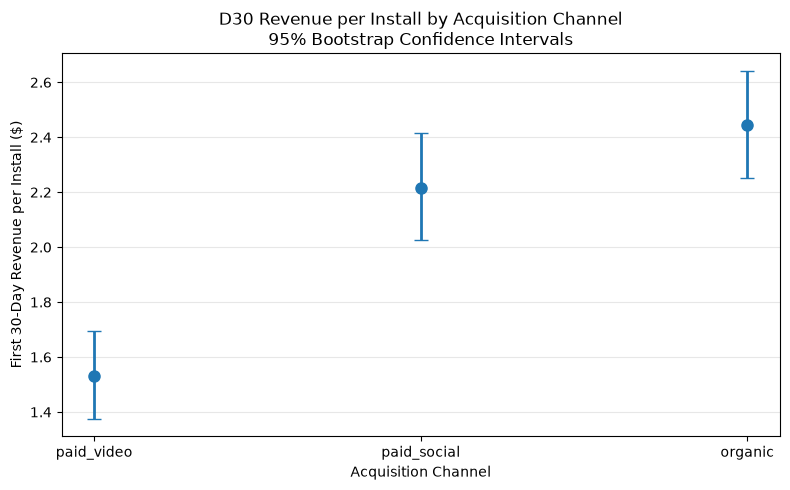

In [55]:
plot_df = revenue_ci.sort_values(
    'mean_d30_revenue'
)

plt.figure(figsize=(8, 5))

plt.errorbar(
    plot_df['channel'],
    plot_df['mean_d30_revenue'],
    yerr=[
        plot_df['mean_d30_revenue'] - plot_df['ci_lower'],
        plot_df['ci_upper'] - plot_df['mean_d30_revenue']
    ],
    fmt='o',
    capsize=5,
    linewidth=2,
    markersize=8
)

plt.ylabel('First 30-Day Revenue per Install ($)')
plt.xlabel('Acquisition Channel')
plt.title(
    'D30 Revenue per Install by Acquisition Channel\n'
    '95% Bootstrap Confidence Intervals'
)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.savefig(
    '../outputs/figures/03_channel_d30_revenue.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

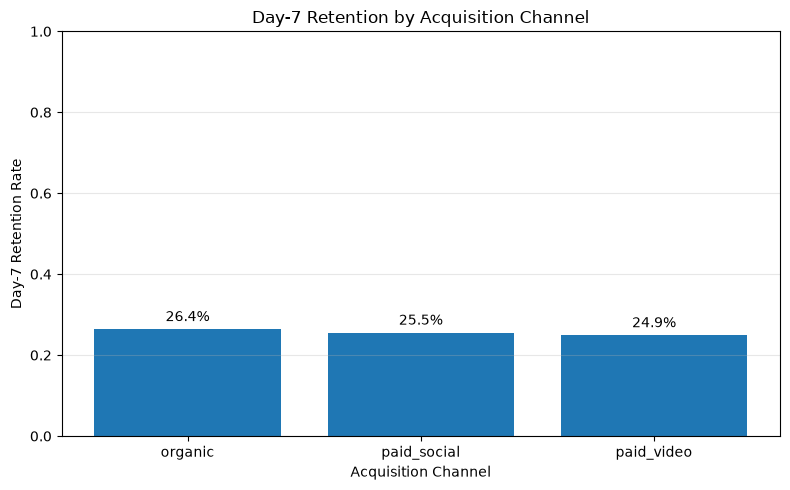

In [56]:
plot_retention = d7_retention.sort_values(
    'd7_retention',
    ascending=False
)

plt.figure(figsize=(8, 5))

plt.bar(
    plot_retention['acquisition_channel'],
    plot_retention['d7_retention']
)

plt.ylabel('Day-7 Retention Rate')
plt.xlabel('Acquisition Channel')
plt.title('Day-7 Retention by Acquisition Channel')

plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)

for i, ret in enumerate(
    plot_retention['d7_retention']
):
    plt.text(
        i,
        ret + 0.02,
        f"{ret:.1%}",
        ha='center'
    )

plt.tight_layout()

plt.savefig(
    '../outputs/figures/03_channel_d7_retention.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

In [57]:
channel_summary.to_csv(
    '../outputs/tables/03_channel_summary.csv',
    index=False
)

monthly_installs.to_csv(
    '../outputs/tables/03_monthly_channel_installs.csv',
    index=False
)

tier_mix.to_csv(
    '../outputs/tables/03_channel_tier_mix.csv',
    index=False
)

d7_retention.to_csv(
    '../outputs/tables/03_d7_retention.csv',
    index=False
)

revenue_summary.to_csv(
    '../outputs/tables/03_d30_revenue.csv',
    index=False
)

tier_channel_revenue.to_csv(
    '../outputs/tables/03_channel_tier_revenue.csv',
    index=False
)

revenue_ci.to_csv(
    '../outputs/tables/03_revenue_confidence_intervals.csv',
    index=False
)

print("All Part 3 outputs saved successfully.")

All Part 3 outputs saved successfully.


## Findings and Recommendation

- Raw D30 revenue per install is lower for `paid_video` than `paid_social`, but the channels have substantially different country-tier compositions.

- After standardizing both channels to the same country-tier distribution, the estimated D30 revenue difference (`paid_video - paid_social`) is only **+$0.063 per install**, with a **95% CI of -$0.224 to $0.358**. Because the interval includes zero, the adjusted revenue difference is not statistically distinguishable from zero.

- D7 retention differs statistically across acquisition channels, but the absolute differences are small: **26.41% organic, 25.52% paid_social, and 24.89% paid_video**.

- Therefore, the observed data does not provide sufficient evidence to recommend shifting acquisition budget between `paid_video` and `paid_social`.

- Marketing spend / CPI is not available, so channel profitability or ROAS cannot be evaluated. Acquisition-cost data should be combined with retention and D30 revenue before making a budget-allocation decision.